In [160]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [161]:
df=pd.read_csv('../Datasets/sentiment.csv')

In [162]:
df.head()

,ID,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,Enjoying a beautiful day at the park! ...,Positive,15-01-2023 12:30,User123,Twitter,#Nature #Park,15,30,USA,2023,1,15,12
1,1,Traffic was terrible this morning. ...,Negative,15-01-2023 08:45,CommuterX,Twitter,#Traffic #Morning,5,10,Canada,2023,1,15,8
2,2,Just finished an amazing workout! 💪 ...,Positive,15-01-2023 15:45,FitnessFan,Instagram,#Fitness #Workout,20,40,USA,2023,1,15,15
3,3,Excited about the upcoming weekend getaway! ...,Positive,15-01-2023 18:20,AdventureX,Facebook,#Travel #Adventure,8,15,UK,2023,1,15,18
4,4,Trying out a new recipe for dinner tonight. ...,Neutral,15-01-2023 19:55,ChefCook,Instagram,#Cooking #Food,12,25,Australia,2023,1,15,19


In [163]:
df['Sentiment']=df['Sentiment'].str.strip()
df['Sentiment']=df['Sentiment'].str.lower()

In [164]:
df['Text']=df['Text'].str.strip()
df['Text']=df['Text'].str.lower()

In [165]:
df['Country']=df['Country'].str.strip()

In [166]:
print(pd.unique(df.Sentiment))

['positive' 'negative' 'neutral' 'anger' 'fear' 'sadness' 'disgust'
 'happiness' 'joy' 'love' 'amusement' 'enjoyment' 'admiration' 'affection'
 'awe' 'disappointed' 'surprise' 'acceptance' 'adoration' 'anticipation'
 'bitter' 'calmness' 'confusion' 'excitement' 'kind' 'pride' 'shame'
 'elation' 'euphoria' 'contentment' 'serenity' 'gratitude' 'hope'
 'empowerment' 'compassion' 'tenderness' 'arousal' 'enthusiasm'
 'fulfillment' 'reverence' 'despair' 'grief' 'loneliness' 'jealousy'
 'resentment' 'frustration' 'boredom' 'anxiety' 'intimidation'
 'helplessness' 'envy' 'regret' 'curiosity' 'indifference' 'numbness'
 'melancholy' 'nostalgia' 'ambivalence' 'determination' 'zest' 'hopeful'
 'proud' 'grateful' 'empathetic' 'compassionate' 'playful' 'free-spirited'
 'inspired' 'confident' 'bitterness' 'yearning' 'fearful' 'apprehensive'
 'overwhelmed' 'jealous' 'devastated' 'frustrated' 'envious' 'dismissive'
 'thrill' 'bittersweet' 'overjoyed' 'inspiration' 'motivation'
 'contemplation' 'joyfulr

In [167]:
df1=df.groupby('Sentiment').value_counts(['Text']).reset_index(name='count')

In [168]:
df1=df1.groupby('Sentiment')['count'].sum().reset_index(name='Count')

In [169]:
df1

,Sentiment,Count
0,acceptance,8
1,accomplishment,3
2,admiration,4
3,adoration,2
4,adrenaline,1
...,...,...
186,winter magic,1
187,wonder,3
188,wonderment,1
189,yearning,2


In [170]:
df2=df1.sort_values(by='Count',ascending=False)

In [171]:
df2=df2.head(20)

C:\Users\Samarth\AppData\Local\Temp\ipykernel_12304\1523628510.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sentiment',y='Count',data=df2,palette='magma')


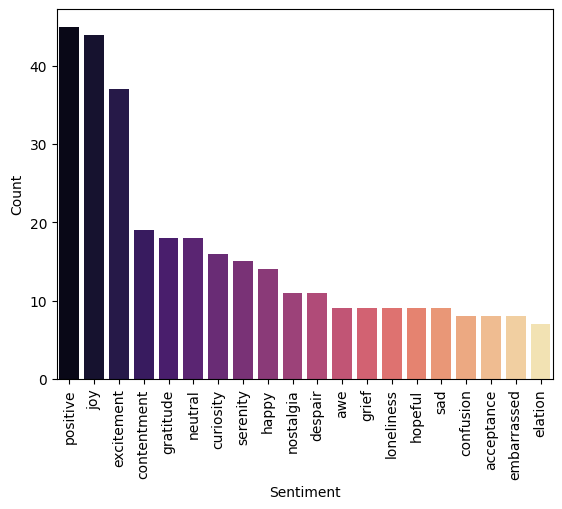

In [172]:
sns.barplot(x='Sentiment',y='Count',data=df2,palette='magma')
plt.xticks(rotation=90)
plt.show()

In [173]:
df.columns

Index(['ID', 'Text', 'Sentiment', 'Timestamp', 'User', 'Platform', 'Hashtags',
       'Retweets', 'Likes', 'Country', 'Year', 'Month', 'Day', 'Hour'],
      dtype='object')

In [174]:
df3=df.groupby('Sentiment')[['Text']].str.len()
df3

AttributeError: 'DataFrameGroupBy' object has no attribute 'str'

In [175]:
df4=df.groupby('Text')['Likes'].mean().reset_index(name='AvgLikes')

In [176]:
df4=df4.head(20)

In [177]:
df4['Text']=df4['Text'].str.slice(0,20)+"..."

C:\Users\Samarth\AppData\Local\Temp\ipykernel_12304\1998917315.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df4,x='Text',y='AvgLikes',palette='magma')


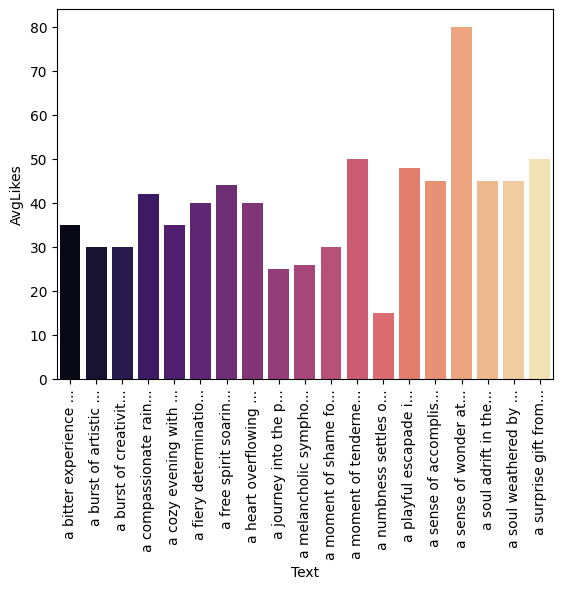

In [178]:
sns.barplot(data=df4,x='Text',y='AvgLikes',palette='magma')
plt.xticks(rotation=90)
plt.show()

In [179]:
df['Retweets'].mean()

np.float64(21.508196721311474)

In [180]:
df5=df.groupby(['Text','Sentiment'])['Retweets'].mean().reset_index(name='AvgRetweets')

In [181]:
df5

,Text,Sentiment,AvgRetweets
0,a bitter experience turned into a valuable les...,bitter,18.0
1,a burst of artistic creativity in the quietude...,artisticburst,15.0
2,a burst of creativity in the quiet solitude of...,creativity,15.0
3,"a compassionate rain, tears of empathy falling...",compassionate,21.0
4,a cozy evening with a good movie.,positive,18.0
...,...,...,...
701,wonderment at the beauty of a double rainbow a...,wonderment,35.0
702,"wrapped in the cloak of emotional numbness, a ...",numbness,10.0
703,"wrestling with thoughts, a perplexed mind lost...",confusion,14.0
704,"yearning for a touch that's not there, echoes ...",yearning,10.0


In [182]:
df6=df5[df5['AvgRetweets']>21.50][['Sentiment','AvgRetweets','Text']]

In [183]:
df6

,Sentiment,AvgRetweets,Text
6,free-spirited,22.0,"a free spirit soaring on the wings of dreams, ..."
12,tenderness,25.0,"a moment of tenderness, connecting with loved ..."
14,playful,24.0,"a playful escapade in the carnival of life, ca..."
15,accomplishment,22.0,a sense of accomplishment after completing a c...
16,wonder,40.0,a sense of wonder at the vastness of the cosmo...
...,...,...,...
691,loss,22.0,whispers of lost love linger in the attic of t...
692,happy,26.0,winning a friendly sports competition against ...
699,heartwarming,22.0,witnessing a heartwarming comeback in the hock...
700,admiration,22.0,"witnessing a record-breaking marathon, spectat..."


In [184]:
df6['Sentiment'].mode()[0]

'joy'

In [185]:
df6[df6['AvgRetweets']>=df6['AvgRetweets'].max()][['Sentiment','AvgRetweets','Text']]

,Sentiment,AvgRetweets,Text
16,wonder,40.0,a sense of wonder at the vastness of the cosmo...
34,disappointment,40.0,"after a series of defeats, the soccer team fac..."
47,anticipation,40.0,anticipation for an upcoming adventure in an e...
62,enthusiasm,40.0,"at a justin bieber concert, the infectious bea..."
67,emotion,40.0,"at the front row of adele's concert, each note..."
96,wonder,40.0,awe-inspired by the vastness of the cosmos on ...
125,excitement,40.0,"captivated by the spellbinding plot twists, th..."
132,joy,40.0,celebrating a historic victory in the world cu...
171,joy,40.0,"dancing on sunshine, each step a celebration o..."
213,elation,40.0,elation over discovering a rare book in a quai...


In [186]:
df7=df[df['Sentiment']=='positive']

In [187]:
df8=df7.groupby('Country').value_counts(['Text']).reset_index(name='count')

In [188]:
df8

,Country,Text,count
0,Australia,quiet evening with a good book.,1
1,Australia,reflecting on the beauty of nature.,1
2,Canada,a cozy evening with a good movie.,1
3,Canada,celebrating a milestone at work! 🎉,1
4,Canada,feeling optimistic about the week ahead.,1
5,Canada,just adopted a cute furry friend! 🐾,1
6,Canada,new painting in progress! 🎨,1
7,Canada,rainy days call for cozy blankets and hot cocoa.,1
8,Canada,trying out a new dessert recipe.,1
9,Canada,winter sports day at the local park.,1


In [189]:
df9=df8.groupby('Country')['count'].sum().reset_index(name='TotalCount')

In [190]:
df9

,Country,TotalCount
0,Australia,2
1,Canada,8
2,India,7
3,UK,10
4,USA,18


C:\Users\Samarth\AppData\Local\Temp\ipykernel_12304\661441699.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df9,x='Country',y='TotalCount',palette='magma')


<Axes: xlabel='Country', ylabel='TotalCount'>

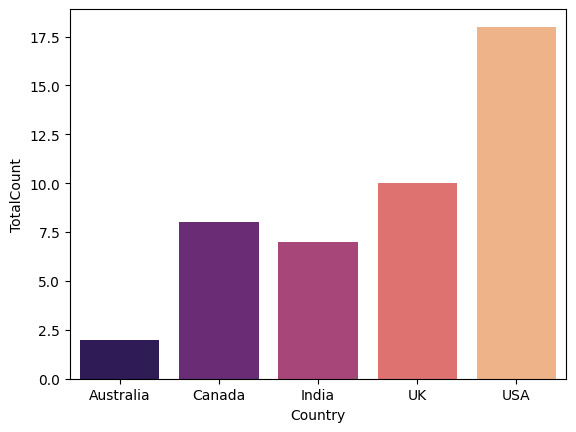

In [191]:
sns.barplot(data=df9,x='Country',y='TotalCount',palette='magma')

In [198]:
df10=df[df['Hashtags'].str.contains('Travel')]

In [199]:
df10

,ID,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
3,3,excited about the upcoming weekend getaway!,positive,15-01-2023 18:20,AdventureX,Facebook,#Travel #Adventure,8,15,UK,2023,1,15,18
72,73,excitement building up for the upcoming vacation!,excitement,18-02-2023 18:45,VacationDreamer,Facebook,#Excitement #TravelPlans,22,45,Canada,2023,2,18,18
84,85,enjoying every moment of this trip—pure enjoym...,enjoyment,23-02-2023 19:45,TravelExplorer,Facebook,#Enjoyment #Travel,25,50,USA,2023,2,23,19
145,146,arousal of excitement before a much-awaited trip.,arousal,10-03-2018 09:45,TravelExcitement,Twitter,#Arousal #TravelAdventure,20,40,India,2018,3,10,9
596,597,spontaneously booked a weekend getaway. advent...,excitement,05-06-2023 10:00,AdventureSeeker,Instagram,#GetawayGoals #TeenTravel,18,35,UK,2023,6,5,10
610,611,embarked on a road trip to revisit cherished p...,joy,19-06-2023 16:30,RoadTripSenior,Facebook,#CherishedPlaces #SeniorTravel,22,45,Canada,2023,6,19,16
622,623,"embarked on a solo travel adventure, discoveri...",excitement,01-07-2023 14:00,SoloAdventurer,Instagram,#DiscoverNewPlaces #SeniorTravel,30,60,USA,2023,7,1,14


In [208]:
df11=df.groupby('Sentiment')['Likes'].mean().reset_index(name='avg')

In [209]:
df11

,Sentiment,avg
0,acceptance,34.125000
1,accomplishment,51.666667
2,admiration,43.750000
3,adoration,45.000000
4,adrenaline,45.000000
...,...,...
186,winter magic,60.000000
187,wonder,73.333333
188,wonderment,70.000000
189,yearning,20.000000


In [210]:
df11[df11['Sentiment']=='negative']['avg']

134    25.0
Name: avg, dtype: float64

In [211]:
df11=df[(df['Likes']>= 25.0) & (df['Sentiment']=='negative')]['Text']

In [212]:
df11

8    political discussions heating up on the timeline.
Name: Text, dtype: object

In [215]:
df12=df[df['Sentiment'].str.contains('appiness')][['User','Text','Sentiment']]

In [216]:
df12

,User,Text,Sentiment
56,ProudFriend,pure happiness: celebrating a loved one's achi...,happiness
80,NewParentJoy,overflowing happiness: welcoming a new family ...,happiness
367,SunnyDayEnthusiast,happiness blooms like flowers in a garden on a...,happiness
471,EchoedLaughter,"laughter echoes in the air, a chorus of happin...",happiness
488,LaughterSymphony,"a symphony of laughter, each note a key to unl...",happiness


In [217]:
df13=df[(df['Sentiment']=='positive')|(df['Sentiment']=='negative')|(df['Sentiment']=='neutral')]

In [218]:
df13

,ID,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,enjoying a beautiful day at the park!,positive,15-01-2023 12:30,User123,Twitter,#Nature #Park,15,30,USA,2023,1,15,12
1,1,traffic was terrible this morning.,negative,15-01-2023 08:45,CommuterX,Twitter,#Traffic #Morning,5,10,Canada,2023,1,15,8
2,2,just finished an amazing workout! 💪,positive,15-01-2023 15:45,FitnessFan,Instagram,#Fitness #Workout,20,40,USA,2023,1,15,15
3,3,excited about the upcoming weekend getaway!,positive,15-01-2023 18:20,AdventureX,Facebook,#Travel #Adventure,8,15,UK,2023,1,15,18
4,4,trying out a new recipe for dinner tonight.,neutral,15-01-2023 19:55,ChefCook,Instagram,#Cooking #Food,12,25,Australia,2023,1,15,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
713,714,participating in a science fair to showcase a ...,neutral,11-10-2023 16:45,ScienceFairParticipationHighSchool,Facebook,#ScienceFair #HighSchoolScience,19,37,USA,2023,10,11,16
714,715,attending a workshop on time management to enh...,neutral,12-10-2023 18:20,TimeManagementWorkshopHighSchool,Twitter,#EfficiencyGoals #HighSchoolSkills,23,44,Canada,2023,10,12,18
715,716,volunteering at a local charity event to give ...,neutral,13-10-2023 12:30,CharityEventVolunteerHighSchool,Instagram,#CommunityService #HighSchoolVolunteer,20,39,UK,2023,10,13,12
716,717,collaborating on a group project to promote te...,neutral,14-10-2023 17:30,GroupProjectCollaborationHighSchool,Facebook,#TeamSpirit #HighSchoolProjects,18,35,USA,2023,10,14,17


In [223]:
df14=df13.groupby(['Country','Year','Sentiment']).size().unstack(fill_value=0)

In [224]:
df14

,Sentiment,negative,neutral,positive
Country,Year,,,
Australia,2023,0,2,2
Canada,2023,2,5,8
India,2023,0,1,7
UK,2023,0,4,10
USA,2023,2,6,18


<Axes: xlabel='Country,Year'>

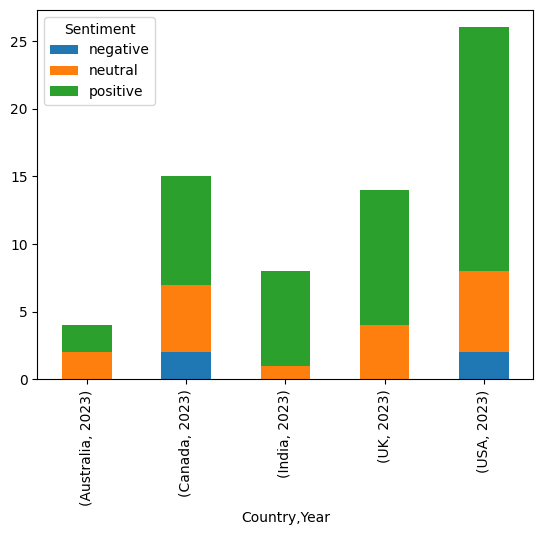

In [226]:
df14.plot(stacked=True,kind='bar')